# Why Some Students Use AI More Than Others

CS105 Fall'26 Mini-Project

## Topic Overview

*Introduce the topic and give context for the data and research questions.*

## Q1: What data do we have?

*Describe the dataset: source, number of responses, and the features we use.*

## Q2: What would we like to know?

*State the questions we aim to investigate.*

## Data Cleaning

*Columns kept/removed, how missing values were handled, any derived scores.*

## Exploratory Data Analysis

### I. Data Exploration and Visualization

*At least 8 visualizations, at least 6 different types. For each: what we want to learn → code → interpretation.*

In [45]:
#Visual 1 data cleaning
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/uncleaned_data.csv")

# answers use a curly apostrophe (’), swap it for a normal one (')
df = df.replace("’", "'", regex=True)

# look through the df to find the 8 "how often do you use AI for..." columns
ai_cols = [c for c in df.columns if c.startswith("How often do you use AI for the following:")]

# look through the df to find the 3 reason columns
learn_col = [c for c in df.columns if "learn the material myself" in c][0]
trust_col = [c for c in df.columns if "trust its answers" in c][0]   # "don't trust its answers"
rules_col = [c for c in df.columns if "class rules" in c][0]

# turn each ai use answer into a number, anything else (blank, prefer not to answer) becomes NaN
to_number = {
    "I don't use AI for this": 0,
    "I use it rarely": 1,
    "I use it sometimes": 2,
    "I use it very often": 3,
}
numbers = pd.DataFrame()
for col in ai_cols:
    numbers[col] = df[col].map(to_number)

# break down the groups like stated in the above markdown cell
reason_groups = {
    "Not at all": "Not at all / A little",
    "A little": "Not at all / A little",
    "Somewhat": "Somewhat",
    "A lot": "A lot",
}

# One row per student with their reliance score (average of the 8 numbers, NaNs skipped) and their three grouped answers.
# NaNs are kept here, seaborn drops them for each panel on its own.
data = pd.DataFrame({
    "reliance_score": numbers.mean(axis=1),
    "learn_myself": df[learn_col].map(reason_groups),
    "no_trust": df[trust_col].map(reason_groups),
    "class_rules": df[rules_col].map(reason_groups),
})

To compare students we needed one number for how much each student uses AI (AI-reliance score).

- [CA]–[CH] "How often do you use AI for the following" asked about 8 tasks, each with 4 options (I don't use AI for this | I use it rarely | I use it sometimes | I use it very often).  
Each becomes a value 0–3 and averaged them, so each student gets one **AI-reliance score** from 0 (never) to 3 (very often). Blanks and "Prefer not to answer" were skipped.

We then focused on the questions that put these students into the different groups that we will be observing.

- [DE] "I want to learn the material myself," [DG] "I don't trust its answers," and [DH] "My class rules don't allow it".  
Each had 4 options (Not at all | A little | Somewhat | A lot).  
"Not at all" and "A little" were small groups so they got combined. "Somewhat" and "A lot" were left as is.

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

df = pd.read_csv("../data/uncleaned_data.csv")

# look through the df to find the 3 "AI without your professor or TA" columns and the stress column
skip_cols = [c for c in df.columns if "without consulting your professor or TA" in c]
stress_col = [c for c in df.columns if "[Stress about coursework]" in c][0]

# turn each answer into a number, anything else (blank, prefer not to answer) becomes NaN
to_number = {"Never": 0, "Rarely": 1, "Sometimes": 2, "Often": 3, "All the time": 4}
numbers = pd.DataFrame()
for col in skip_cols:
    numbers[col] = df[col].map(to_number)

# break down the groups like stated in the above markdown cell
ai_instead = pd.cut(numbers.mean(axis=1), bins=[-1, 1, 2, 4], labels=["Rarely", "Sometimes", "Often"])
stress = pd.cut(pd.to_numeric(df[stress_col], errors="coerce"), bins=[0, 3, 5],
                labels=["Less stressed (1-3)", "Very stressed (4-5)"])

# One row per student. Drop students who skipped either question.
data = pd.DataFrame({
    "ai_instead": ai_instead,
    "stress": stress,
}).dropna()

To compare students we needed one number for how much each student uses AI (AI-reliance score).

- [CA]–[CH] "How often do you use AI for the following" asked about 8 tasks, each with 4 options (I don't use AI for this | I use it rarely | I use it sometimes | I use it very often).  
Each becomes a value 0–3 and averaged them, so each student gets one **AI-reliance score** from 0 (never) to 3 (very often). Blanks and "Prefer not to answer" were skipped.

We then focused on the questions that put these students into the different groups that we will be observing.

- [DE] "I want to learn the material myself," [DG] "I don't trust its answers," and [DH] "My class rules don't allow it".  
Each had 4 options (Not at all | A little | Somewhat | A lot).  
"Not at all" and "A little" were small groups so they got combined. "Somewhat" and "A lot" were left as is.

In [40]:
#Visual 3 data cleaning
import pandas as pd

# Load the original dataset
df = pd.read_csv("../data/uncleaned_data.csv")

# Keep the original dataset unchanged
df_raw = df.copy()

# Create analysis dataframe
df_sankeyAnalysis = pd.DataFrame()

df_sankeyAnalysis["ai_days"] = pd.to_numeric(df[next(col for col in df.columns if "on how many days did you use AI tools for schoolwork" in col)],errors="coerce")

df_sankeyAnalysis["ai_minutes"] = pd.to_numeric(df[next(col for col in df.columns if "Total minutes:" in col)],errors="coerce")

df_sankeyAnalysis["main_reason"] = df[next(col for col in df.columns
if "main reason for using AI" in col)]

df_sankeyAnalysis["reliance_after_procrastinating"] = df[next(col for col in df.columns
if "I find myself relying on AI more after I procrastinate" in col)]

df_sankeyAnalysis["homework_timing"] = df[next(col for col in df.columns
if "How far in advance do you typically begin working" in col
and "[Homework]" in col)]

df_sankeyAnalysis["coursework_stress"] = pd.to_numeric(df[next(col for col in df.columns
if "[Stress about coursework]" in col)],errors="coerce")

# Clean text columns
text_columns = ["main_reason","reliance_after_procrastinating","homework_timing"]

for col in text_columns:
    df_sankeyAnalysis[col] = df_sankeyAnalysis[col].str.strip()



## ADD DATA CLEANING QUICK EXPLANATION

In [41]:
#Visual 4 data cleaning
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

survey_df = pd.read_csv("../data/uncleaned_data.csv")
# create crosstable that limit x-axis as "i don't use AI for this, i use it rarelly, etc"
# y-axis as types of questions: "reviewing lecture slides, doing homework for STEM related subjects, etc"
study_df = survey_df.loc[:, "How often do you use AI for the following:\r\n [Reviewing Lecture slides]":"How often do you use AI for the following:\r\n [Asking for definitions]"]
study_df["How often do you use AI for the following:\r\n [Reviewing Lecture slides]"].value_counts()

# Count responses for each study activity
lecture = study_df.iloc[:, 0].value_counts()
coding = study_df.iloc[:, 1].value_counts()
stem = study_df.iloc[:, 2].value_counts()
writing = study_df.iloc[:, 3].value_counts()
calculation = study_df.iloc[:, 4].value_counts()
written_review = study_df.iloc[:, 5].value_counts()
questions = study_df.iloc[:, 6].value_counts()
definitions = study_df.iloc[:, 7].value_counts()



# Combine response counts into one DataFrame
cross_survey = pd.DataFrame({
    "Reviewing Lecture Slides": lecture,
    "Coding Assignments": coding,
    "STEM Homework": stem,
    "Writing Assignments": writing,
    "Calculation Mistakes": calculation,
    "Written Mistakes": written_review,
    "Asking Questions": questions,
    "Asking Definitions": definitions
}).T.fillna(0)

# Reorder the response categories
response_order = ["I use it very often", "I use it sometimes", "I use it rarely", "I don’t use AI for this", "Prefer not to answer"]

cross_survey = cross_survey.reindex(columns=response_order, fill_value=0)

# Calculate percentages
percentage_survey = (cross_survey.div(cross_survey.sum(axis=1), axis=0) * 100)


For the heatmap, we first loaded the original uncleaned_data.csv dataset using pandas. We selected only the eight survey questions related to how frequently students use AI for different study activities, such as reviewing lecture slides, completing homework, reviewing mistakes, and asking questions.

Next, we used value_counts() to count how many students selected each response for every study activity. We then combined these counts into a new DataFrame using pd.DataFrame() and transposed it so that each row represented a study activity and each column represented an AI usage frequency.

We used fillna(0) to replace missing response counts with zero and reindex() to arrange the five frequency categories in a consistent order, from "I use it very often" to "Prefer not to answer" so it follows our original google form. Then we divided each response count by the total number of responses for that activity and multiplied by 100 to convert the counts into percentages.

This preparation allowed us to compare AI usage frequencies across all eight study activities using a heatmap.

Add on to correlation test:
For the correlation test, we selected two study activities from the heatmap dataset: asking questions and reviewing calculation mistakes. We converted the frequency responses into numerical values from 0 to 3, where 0 represents not using AI and 3 represents using AI very often.

We then combined the two variables into a new DataFrame and used dropna() to remove students with missing or non-frequency responses for either activity. This produced 83 valid paired responses for the Spearman correlation analysis.

In [42]:
#Visual 5 data cleaning
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

survey_df = pd.read_csv("../data/uncleaned_data.csv")

# Clean up the data by selecting the three homework strategy questions
homework_df = survey_df.loc[:, "If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take in each of the following scenarios? [When you have more than enough time to finish your assignment before the deadline]" : "If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take in each of the following scenarios? [When you don’t have enough time to finish your assignment before the deadline]"]

# Count the responses for each deadline situation
more_time = homework_df.iloc[:, 0].value_counts()
just_enough = homework_df.iloc[:, 1].value_counts()
not_enough = homework_df.iloc[:, 2].value_counts()

# Combine the counts into one DataFrame
cross_homework = pd.DataFrame({
    "More than enough time": more_time,
    "Just enough time": just_enough,
    "Not enough time": not_enough
}).T

# Replace missing response with 0
cross_homework = cross_homework.fillna(0)

# Set the order of homework strategies
strategy_order = [
    "Trying on my own",
    "Seek help from a classmate or TA",
    "Ask AI for a hint or explanation",
    "Ask AI for the complete solution",
    "Leave the problem as incomplete"
]

# Reorder the columns
cross_homework = cross_homework.reindex(columns=strategy_order, fill_value=0)


# Calculate the percentage of each homework strategy for each deadline situation
# Divide each count by the total responses in its row
percentage_homework = cross_homework.div(cross_homework.sum(axis=1), axis=0) * 100

For the stacked bar chart, we loaded the original uncleaned_data.csv dataset and selected only the three survey questions about students' preferred homework strategies under different deadline conditions: more than enough time, just enough time, and not enough time.

We used value_counts() to count the responses for each deadline situation and combined the counts into one DataFrame. Each row represented a different deadline condition, while each column represented a homework strategy, such as trying independently, asking a classmate or TA, asking AI for hints or explanations, asking AI for a complete solution, or leaving the problem incomplete.

Next, we used fillna(0) to replace missing response counts with zero and reindex() to arrange the homework strategies in a consistent order. We then divided each response count by the total responses for that deadline condition and multiplied by 100 to calculate the percentages.

This preparation ensured that each deadline condition totaled 100%, allowing us to compare the distribution of homework strategies using a 100% stacked bar chart.

In [53]:
#Visual 6 data cleaning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

survey_df = pd.read_csv("../data/uncleaned_data.csv")

cols = list(survey_df.columns)
help_col = [c for c in cols if "AI has helped me feel less stressed" in c][0]
agree_scale = {"Strong disagree": 1, "Disagree": 2, "Neutral": 3, "Agree": 4, "Strong agree": 5}
group_names = {1: "Strongly\ndisagree", 2: "Disagree", 3: "Neutral", 4: "Agree", 5: "Strongly\nagree"}


stress_col = [c for c in cols if "past 7 days how much did you experience" in c and "Stress about coursework" in c][0]
minutes_col = [c for c in cols if c.startswith("In the past 7 days, approximately how many minutes")][0]

df = pd.DataFrame({
    "help": survey_df[help_col].astype(str).str.strip().map(agree_scale),
    "stress": pd.to_numeric(survey_df[stress_col], errors="coerce"),
    "minutes": pd.to_numeric(survey_df[minutes_col], errors="coerce"),
}).dropna()

# One bubble per answer group
groups = sorted(df["help"].unique())
stress_avg = [df.loc[df.help == g, "stress"].mean() for g in groups] 
minutes_med = [df.loc[df.help == g, "minutes"].median() for g in groups]
students = [int((df.help == g).sum()) for g in groups]
labels = [group_names[int(g)] for g in groups]
colors = {1: "#d7191c", 2: "#fdae61", 3: "#ffffbf", 4: "#abd9e9", 5: "#2c7bb6"}
bubble_colors = [colors[int(g)] for g in groups]

for lab, n, x_, y_ in zip(labels, students, stress_avg, minutes_med):
    print(f"{lab.replace(chr(10), ' '):<20} n={n:<3} avg stress={x_:.2f}  median minutes={y_:.0f}")

Strongly disagree    n=9   avg stress=3.11  median minutes=0
Disagree             n=5   avg stress=2.60  median minutes=60
Neutral              n=22  avg stress=3.59  median minutes=35
Agree                n=30  avg stress=4.00  median minutes=120
Strongly agree       n=12  avg stress=4.17  median minutes=120




Here I pulled data from three questions: how much users agree AI decreased stress, their actual stress levels, and the amount of AI used in the last 7 days. I numerized the response on the scale from strong disagree to strong agree from 1-5 to plot it on the graph. I bubbled similar answers together for the question of if they agreed AI decreased stress and plotted it with the x-axis representing the stress levels and y-axis representing the amount of AI used in the last 7 days.

In [55]:
#Visual 7 data cleaning
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

survey_df = pd.read_csv("../data/uncleaned_data.csv")

proc_df = survey_df.loc[:, "If you procrastinate, what do you typically spend your time doing?  [Sleeping/Napping]":
                           "If you procrastinate, what do you typically spend your time doing?  [Gaming]"].copy()
proc_df.columns = ["Sleeping/\nNapping", "Hanging Out\nwith Friends", "Easier\nAssignments", "Shows/\nMovies", "Social\nMedia", "Gaming"]

minutes_col = [c for c in survey_df.columns if c.startswith("In the past 7 days, approximately how many minutes")][0]
ai_col = "Average Minutes\nof AI Used"
raw_ai_col = "raw_minutes"
proc_df[raw_ai_col] = pd.to_numeric(survey_df[minutes_col], errors="coerce")

# Convert the answers into values 1 to 5
scale = {"Never": 1, "Rarely": 2, "Sometimes": 3, "Often": 4, "Always": 5}
procrastination_types = [c for c in proc_df.columns if c != raw_ai_col]
for col in procrastination_types:
    proc_df[col] = proc_df[col].map(scale)

# Remove rows with blank values
proc_df = proc_df.dropna()


ai_cutoff = 400
n_before = len(proc_df)
proc_df = proc_df[proc_df[raw_ai_col] <= ai_cutoff]
n_removed = n_before - len(proc_df)


overall_col = "Overall\nProcrastination"
proc_df[overall_col] = proc_df[procrastination_types].mean(axis=1)


bucket_size = 50
edges = list(range(0, ai_cutoff + 1, bucket_size))
bucket_labels = [f"{lo + 1}-{hi} min" for lo, hi in zip(edges[:-1], edges[1:])]
proc_df["bucket"] = pd.cut(proc_df[raw_ai_col], bins=edges, labels=bucket_labels, include_lowest=True)


value_cols = [raw_ai_col] + procrastination_types + [overall_col]
bucket_means = proc_df.groupby("bucket", observed=True)[value_cols].mean()
bucket_n = proc_df.groupby("bucket", observed=True).size()
bucket_means = bucket_means.rename(columns={raw_ai_col: ai_col})


ai_ticks = [0, 100, 200, 300, 400]

scaled_df = pd.DataFrame(index=bucket_means.index)
scaled_df[ai_col] = bucket_means[ai_col] / ai_cutoff
for col in procrastination_types + [overall_col]:
    scaled_df[col] = (bucket_means[col] - 1) / 4

columns = [ai_col] + procrastination_types + [overall_col]
x = np.arange(len(columns))

# One color per bucket (light to dark as AI use goes up)
cmap = plt.cm.viridis
bucket_colors = {b: cmap(0.05 + 0.85 * i / (len(bucket_labels) - 1)) for i, b in enumerate(bucket_labels)}




Here I pulled data from multiple different sources. Specifically the survey questions that inquired about different amounts of procrasinations from working on other to assignments to gaming or watching shows. Afterwards, I separated them into different columns and turned the responses into numerical values I could plot on the graphs. I then pulled data from how many minutes of AI used in the last 7 days to create the buckets for in increments of 50 minutes. For the last touch, I added an overall total procrasination column at the end to track overall procrasination. I did additionally remove any responses that either did not answer the survey questions or had minutes of AI use that seemed like outliers (answers over 400 minutes).

In [ ]:
#Visual 8 data cleaning
from pathlib import Path
import hashlib
import pandas as pd

# Locate the repository whether launched from this folder or the repository root.
repo_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'data' / "uncleaned_data.xlsx").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Could not locate data/uncleaned_data.xlsx in the repository.')
source_path = repo_root / 'data' / "uncleaned_data.xlsx"
output_dir = repo_root / 'working_folders' / 'slian088'
data = pd.read_excel(source_path, sheet_name='Form Responses 1')
print(f'Source: {source_path.relative_to(repo_root)}')
print(f'Responses: {len(data)}; columns: {data.shape[1]}')
print('Workbook SHA-256:', hashlib.sha256(source_path.read_bytes()).hexdigest())

factors = {
    'learn_myself': ('DE', 'I want to learn the material myself'),
    'future_independence': ('DF', 'I need to be able to do it without AI later'),
    'distrust_answers': ('DG', 'I don’t trust its answers'),
    'class_rules': ('DH', "My class rules don't allow it"),
    'feels_like_cheating': ('DI', 'I feel like I am cheating'),
    'lack_of_ai_skills': ('DJ', "I don't know how to use it well"),
}
selected = {}
for short_name, (excel_col, wording) in factors.items():
    matches = [c for c in data.columns
               if c.startswith('When you are working on a homework assignment,')
               and c.strip().endswith(f'[{wording}]')]
    if len(matches) != 1:
        raise ValueError(f'Expected exactly one column for {short_name}: {matches}')
    selected[matches[0]] = short_name

raw_factors = data[list(selected)].rename(columns=selected).copy()
raw_factors.index = pd.RangeIndex(2, len(data) + 2, name='source_excel_row')
variable_dictionary = pd.DataFrame([
    {'variable': name, 'original_excel_column': col, 'factor': wording}
    for name, (col, wording) in factors.items()
])
print(variable_dictionary.to_string(index=False))
print('\nFirst five responses (original text):')
print(raw_factors.head().to_string())

score_map = {'Not at all': 0, 'A little': 1, 'Somewhat': 2, 'A lot': 3}
text_factors = raw_factors.apply(lambda col: col.astype('string').str.strip())
text_factors = text_factors.replace('', pd.NA)
unexpected = {
    col: sorted(set(text_factors[col].dropna()) - set(score_map))
    for col in text_factors
}
unexpected = {col: values for col, values in unexpected.items() if values}
if unexpected:
    raise ValueError(f'Unrecognized survey answers: {unexpected}')
clean_factors = text_factors.apply(lambda col: col.map(score_map)).astype('Int64')

missingness = pd.DataFrame({
    'valid_n': clean_factors.count(),
    'missing_n': clean_factors.isna().sum(),
})
print(missingness.to_string())
print(f'\nResponses with all six factors answered: {len(clean_factors.dropna())}')
print(f'Responses with no factors answered: {clean_factors.isna().all(axis=1).sum()}')
print('\nFirst five encoded responses (NA means missing):')
print(clean_factors.head().to_string())

valid_n = clean_factors.count()
high_count = clean_factors.ge(2).sum()
summary = pd.DataFrame({
    'factor': [factors[name][1] for name in clean_factors.columns],
    'valid_n': valid_n,
    'missing_n': clean_factors.isna().sum(),
    'mean_score': clean_factors.mean(),
    'median_score': clean_factors.median(),
    'somewhat_or_a_lot_n': high_count,
    'somewhat_or_a_lot_pct': high_count.div(valid_n.replace(0, float('nan'))).mul(100),
})
summary.index.name = 'variable'
summary = summary.sort_values('mean_score', ascending=False)
print(summary.to_string(index=False, float_format=lambda x: f'{x:.2f}'))

counts = pd.DataFrame({
    col: text_factors[col].value_counts().reindex(list(score_map), fill_value=0)
    for col in text_factors
}).T
counts.index.name = 'variable'
percentages = counts.div(valid_n.replace(0, float('nan')), axis=0).mul(100)
print('\nFull response counts:')
print(counts.to_string())
print('\nPercentages among valid answers:')
print(percentages.round(2).to_string())



Source: data\uncleaned_data.xlsx
Responses: 93; columns: 175
Workbook SHA-256: 278beaf658088440762c000a3b362a01e9a7d88120c711e122c3e135240831c0
           variable original_excel_column                                      factor
       learn_myself                    DE         I want to learn the material myself
future_independence                    DF I need to be able to do it without AI later
   distrust_answers                    DG                   I don’t trust its answers
        class_rules                    DH               My class rules don't allow it
feels_like_cheating                    DI                   I feel like I am cheating
  lack_of_ai_skills                    DJ             I don't know how to use it well

First five responses (original text):
                 learn_myself future_independence distrust_answers class_rules feels_like_cheating lack_of_ai_skills
source_excel_row                                                                                  

## Data cleaning summary

- Keep the six homework-deterrent questions and class standing. Trim spaces and keep blanks as missing.
- Code Not at all = 0, A little = 1, Somewhat = 2, and A lot = 3. Flag unexpected answers.
- For the radar chart, keep Freshman–Senior and use valid answers per item. Exclude the one concurrent response from this chart.
- For paired tests, require all four score items. Average independent learning and future independence for the learning score; average distrust and difficulty using AI for the trust/skill score.
- For the chi-squared test, require both class-rule and cheating answers. Group scores 0–1 as Lower and 2–3 as Higher.

#### Visualization 1: <title>

**What we want to learn:**

# Question: Do what students say match how much they use AI?




I want to learn the material myself
                       count  median
learn_myself                        
Not at all / A little     23    2.25
Somewhat                  25    1.75
A lot                     36    1.38

I don't trust its answers
                       count  median
no_trust                            
Not at all / A little     40    2.00
Somewhat                  32    1.75
A lot                     12    0.50

My class rules don't allow it
                       count  median
class_rules                         
Not at all / A little     29    1.38
Somewhat                  26    1.75
A lot                     28    1.75



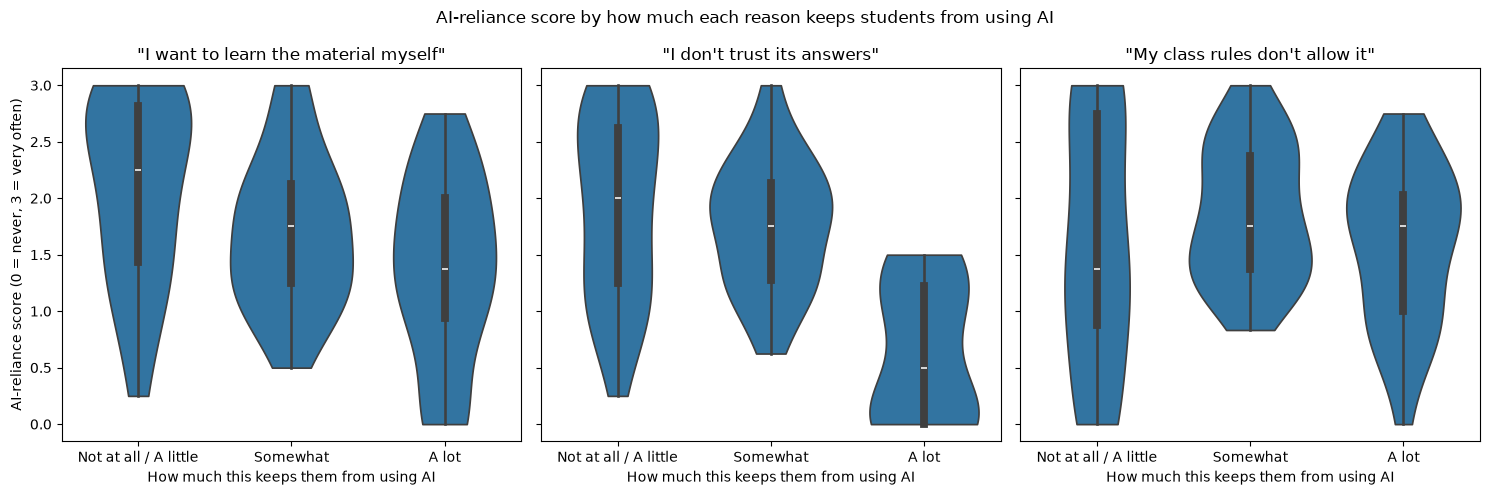

In [46]:
# violin ordering
order = ["Not at all / A little", "Somewhat", "A lot"]

# panel title -> column in data
reasons = {
    "I want to learn the material myself": "learn_myself",
    "I don't trust its answers": "no_trust",
    "My class rules don't allow it": "class_rules",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

i = 0
for title, col in reasons.items():
    # sns.violinplot(data=data, x=col, y="reliance_score", order=order, ax=axes[i])
    sns.violinplot(data=data, x=col, y="reliance_score", order=order, cut=0, ax=axes[i])
    axes[i].set_title(f'"{title}"')
    axes[i].set_xlabel("How much this keeps them from using AI")

    # number of students and median score for each group
    print(title)
    print(data.groupby(col)["reliance_score"].agg(["count", "median"]).loc[order].round(2))
    print()

    i += 1

axes[0].set_ylabel("AI-reliance score (0 = never, 3 = very often)")
fig.suptitle("AI-reliance score by how much each reason keeps students from using AI")
plt.tight_layout()
plt.show()

**Interpretation:**
## Violin

- The idea is to find out what holds back students from using AI. We are looking at two personal reasons and one external reason. Does what they say, hold true?

- **Broad Question A**: "When you are working on a homework assignment, how much does each of these keep you from using AI?"
    - Sub questions:
        - "I want to learn the material myself"; (Not alot | a little | somewhat | a lot)
        - "I dont trust its answers"; (Not alot | a little | somewhat | a lot)
        - "My class rules dont allow it" (Not alot | a little | somewhat | a lot)

- We use these "groups" to essentially try and find out if what students say, holds true with there actions. 

- To test this we need to somehow compute an **AI-reliance score**. There is the **Broad Question B**, "How often do you use AI for the following", that was followed by 8 subquestions where students could answer (dont use ai for this | use is rarely | use is sometimes | use it often). The values are 0-3 with not using AI is 0 and using it often is 3. We sum the scores and average to build the score.

    - The limitations of this score are that they build it based on a single questions with its subquestions. We could extend this and try and build a better score from all features giving weight to some over others to build a more reliable score and capture students who may not have answered this question.

After building the AI score we can plot the results. All subplots share the same y axis and x axis. On the y axis we have the **AI-reliance score** and on the x-axis we have the options to the sub questions in **Broad Question A**. Each of the subplots represents one of the sub questions in **Broad Question A**. The idea here is to isolate the reasons that keep students from using AI and to see if there is a trend as these reasons matter more to students.




#### Visualization 2: <title>

**What we want to learn:**

# Question: When students are stressed, do they seek AI over their professor/TA?


ai_instead           Rarely  Sometimes  Often
stress                                       
Less stressed (1-3)      13         17      4
Very stressed (4-5)       7         17     25

ai_instead           Rarely  Sometimes  Often
stress                                       
Less stressed (1-3)    38.0       50.0   12.0
Very stressed (4-5)    14.0       35.0   51.0

Squares out of 100:
ai_instead           Rarely  Sometimes  Often
stress                                       
Less stressed (1-3)      38         50     12
Very stressed (4-5)      14         35     51


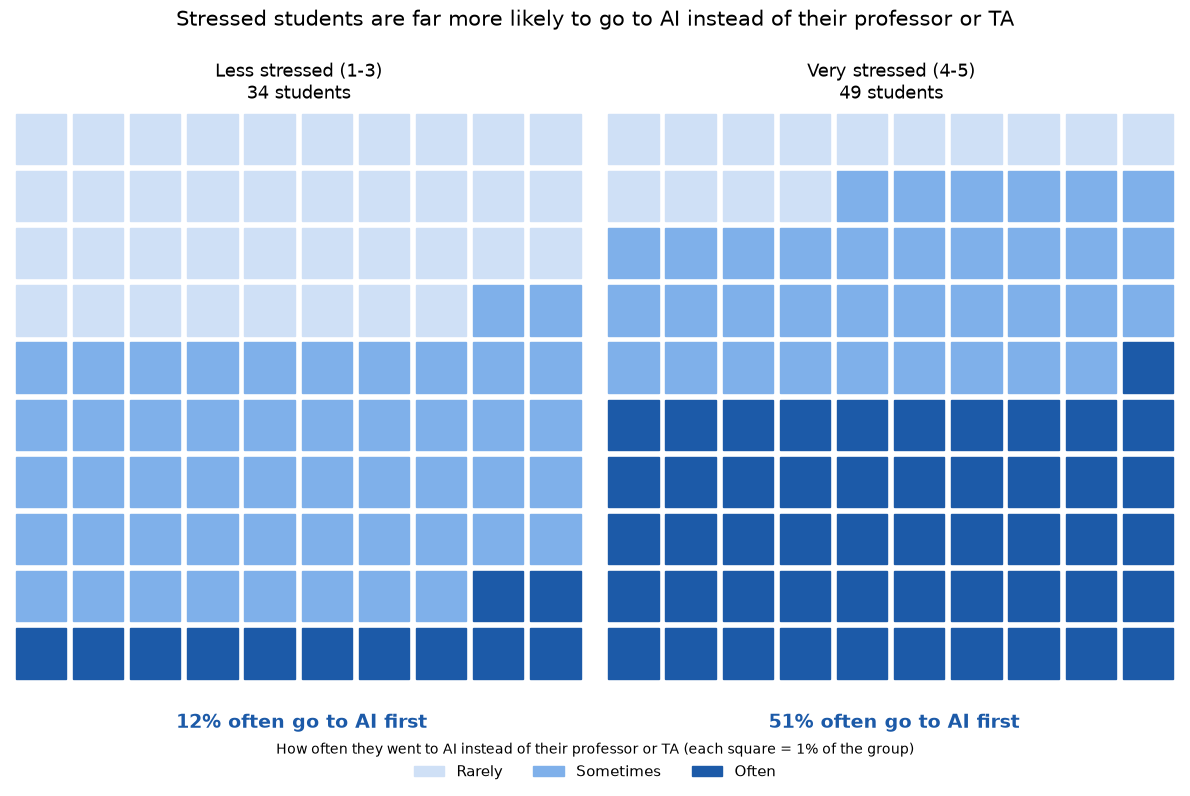


Understanding a course concept: Less stressed (1-3) 26%, Very stressed (4-5) 65%
Understanding what an assignment is asking: Less stressed (1-3) 12%, Very stressed (4-5) 31%
Figuring out how to solve a problem: Less stressed (1-3) 9%, Very stressed (4-5) 41%


In [50]:
# order
stress_order = ["Less stressed (1-3)", "Very stressed (4-5)"]
ai_order = ["Rarely", "Sometimes", "Often"]

# lighter = less AI, darker = more AI
colors = {"Rarely": "#cfe0f6", "Sometimes": "#7fb0ea", "Often": "#1c5aa8"}

# number and percent of students in each group
table = pd.crosstab(data["stress"], data["ai_instead"]).loc[stress_order, ai_order]
percent = (table.div(table.sum(axis=1), axis=0) * 100).round(0)
print(table)
print()
print(percent)

# both groups get a 10 x 10 grid, so each square is 1% of that group
columns = 10
rows = 10

# turn each group's percents into 100 whole squares
# round down first, then give any leftover squares to the answers that lost the most from rounding
square_counts = percent.copy()
for group in stress_order:
    exact = table.loc[group] / table.loc[group].sum() * 100
    whole = exact.astype(int)
    leftover = 100 - whole.sum()
    biggest_remainders = (exact - whole).sort_values(ascending=False).index[:leftover]
    whole[biggest_remainders] += 1
    square_counts.loc[group] = whole
square_counts = square_counts.astype(int)
print()
print("Squares out of 100:")
print(square_counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 8))

i = 0
for group in stress_order:
    ax = axes[i]

    # 100 squares, Rarely first and Often last so each color is one block
    squares = []
    for answer in ai_order:
        squares += [answer] * square_counts.loc[group, answer]

    # fill left to right, top to bottom
    for n, answer in enumerate(squares):
        x = n % columns
        y = rows - 1 - n // columns
        ax.add_patch(Rectangle((x, y), 0.88, 0.88, color=colors[answer]))

    ax.set_xlim(-0.1, columns)
    ax.set_ylim(-0.1, rows)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{group}\n{table.loc[group].sum()} students", fontsize=13)

    # the one number to remember, under each grid
    often = percent.loc[group, "Often"]
    ax.text(columns / 2, -0.6, f"{often:.0f}% often go to AI first", ha="center", va="top",
            fontsize=14, fontweight="bold", color=colors["Often"])

    i += 1

legend = [Patch(color=colors[a], label=a) for a in ai_order]
fig.legend(handles=legend, loc="lower center", ncol=3, frameon=False, fontsize=11,
           title="How often they went to AI instead of their professor or TA (each square = 1% of the group)",
           bbox_to_anchor=(0.5, 0))
fig.suptitle("Stressed students are far more likely to go to AI instead of their professor or TA", fontsize=15)
# leave room at the top for the title and at the bottom for the legend
plt.tight_layout(rect=[0, 0.1, 1, 0.94])
plt.show()

# same thing for each task on its own: percent who said Often or All the time
print()
for col in skip_cols:
    task = col.split("[")[-1].strip("]")
    answered = pd.DataFrame({"stress": stress, "answer": numbers[col]}).dropna()
    often_pct = (answered["answer"] >= 3).groupby(answered["stress"], observed=True).mean() * 100
    print(f"{task}: " + ", ".join(f"{g} {p:.0f}%" for g, p in often_pct.loc[stress_order].items()))

**Interpretation:**

163. [FG] During the past 7 days how much did you experience each of the following, on a scale of 1-5? [Stress about coursework]

165. [FI] When you needed help with the following tasks during the past 7 days, how often did you consult AI without consulting your professor or TA? [Understanding a course concept]
166. [FJ] When you needed help with the following tasks during the past 7 days, how often did you consult AI without consulting your professor or TA? [Understanding what an assignment is asking]
167. [FK] When you needed help with the following tasks during the past 7 days, how often did you consult AI without consulting your professor or TA? [Figuring out how to solve a problem]


What we suspect

Students were asked how often, in the past week, they went to AI for help without going to their professor or TA, for three things: understanding a course concept, understanding what an assignment is asking, and figuring out how to solve a problem. We compared students who felt very stressed about their coursework with students who felt less stressed. We expect that stressed students are more likely to skip their professor or TA and go straight to AI.

Our analysis

We turned the 3 [FI]-[FK] answers into numbers (Never = 0, Rarely = 1, Sometimes = 2, Often = 3, All the time = 4) and averaged them, so each student gets one score from 0 to 4. Blanks and "Prefer not to answer" were skipped. We then put students into 3 groups: Rarely (score 0-1), Sometimes (above 1, up to 2), and Often (above 2).

For stress, [FG] was on a scale of 1-5. Only 10 students answered 1 or 2, so we split students into Less stressed (1-3) and Very stressed (4-5). 83 students answered both questions: 34 less stressed and 49 very stressed.

Because the two groups are different sizes, each group is scaled to a 10 x 10 grid of 100 squares, so each square is 1% of that group (not one student). This keeps the two grids the same size so they can be compared directly. Squares are sorted Rarely -> Sometimes -> Often (light -> dark blue), so the "Often" students form one dark block. No hypothesis test for this graph, just the plot and a light interpretation.

Findings (percent of each group)

                          Rarely   Sometimes   Often
- Less stressed (n = 34):   38%       50%       12%    (13, 17, 4 students)
- Very stressed (n = 49):   14%       35%       51%    (7, 17, 25 students)

Each task on its own (percent who said Often or All the time, less stressed -> very stressed):
- Understanding a course concept: 26% -> 65%. Biggest gap.
- Figuring out how to solve a problem: 9% -> 41%.
- Understanding what an assignment is asking: 12% -> 31%.

Conclusion

When students are stressed, AI replaces their professor or TA as the first place they go for help. Out of every 100 very stressed students, 51 often went to AI first, compared to 12 out of every 100 less stressed students, and the same pattern shows up for every task on its own. From a survey we can't tell which causes which: stressed students might not have time for office hours, or relying on AI might leave students more stressed.


How to read the chart (for presenting)

- Two grids, one per stress group. Each grid is 100 squares, each square = 1% of that group.
- Lighter square = rarely goes to AI instead of the professor/TA, darker = often does.
- The number under each grid is the headline: 12% vs. 51% often go to AI first.
- One-line takeaway: "Out of every 100 stressed students, 51 go to AI before their professor. For less stressed students, it's 12."


#### Visualization 3: <title>

**What we want to learn:**

# Question:

In [51]:
import plotly.graph_objects as go

sankey_data = df_sankeyAnalysis[["reliance_after_procrastinating","ai_days","main_reason"]].copy()


sankey_data = sankey_data.dropna(subset=["reliance_after_procrastinating","ai_days","main_reason"]).copy()


def categorize_days(days):
    if days == 0:
        return "No AI use"
    elif days <= 2:
        return "1 to 2 days"
    elif days <= 4:
        return "3 to 4 days"
    else:
        return "5 to 7 days"

sankey_data["ai_usage"] = sankey_data["ai_days"].apply(categorize_days)


sankey_data["main_reason"] = (sankey_data["main_reason"].astype(str).str.replace(r"Generating answers,\s*text,\s*or code","Generating answers text or code",regex=True,case=False))


sankey_data["main_reason"] = (sankey_data["main_reason"].str.split(r"\s*,\s*"))

sankey_data = sankey_data.explode("main_reason")


sankey_data["main_reason"] = (sankey_data["main_reason"].str.replace("Generating answers text or code", "Generating answers, text, or code",regex=False).str.strip())


conflicts = (sankey_data["main_reason"].str.contains("Did not use AI",case=False,na=False) & (sankey_data["ai_days"] > 0))

print("Conflicting responses:", conflicts.sum())

sankey_data.loc[conflicts, "main_reason"] = "Conflicting responses"


print("Total respondent-reason paths:", len(sankey_data))
print("Unique students:", sankey_data.index.nunique())


reliance_categories = ["Never","Rarely","Sometimes","Often","Always"]

usage_categories = ["No AI use","1 to 2 days","3 to 4 days","5 to 7 days"]

reason_categories = sorted(sankey_data["main_reason"].unique())


nodes = (["Reliance: " + x for x in reliance_categories] + ["AI Usage: " + x for x in usage_categories] + ["Reason: " + x for x in reason_categories])

node_ids = {label: i for i, label in enumerate(nodes)}

sources = []
targets = []
values = []


def add_connections(source_col,target_col,source_prefix,target_prefix):
    grouped = (sankey_data.groupby([source_col, target_col]).size().reset_index(name="count"))

    for _, row in grouped.iterrows():
        source = source_prefix + str(row[source_col])
        target = target_prefix + str(row[target_col])
        sources.append(node_ids[source])
        targets.append(node_ids[target])
        values.append(row["count"])


add_connections("reliance_after_procrastinating","ai_usage","Reliance: ","AI Usage: ")


add_connections("ai_usage","main_reason","AI Usage: ","Reason: ")


fig = go.Figure(data=[go.Sankey(arrangement="snap",node=dict(pad=25,thickness=22,line=dict(color="black",width=0.5),label=nodes),link=dict(source=sources,target=targets,value=values))])

fig.update_layout(title_text="Student Procrastination, AI Usage, and Individual Motivations",font_size=12,height=800,width=1200)

fig.show()


Conflicting responses: 2
Total respondent-reason paths: 180
Unique students: 78


**Interpretation:**

#### Visualization 4: <title>

**What we want to learn:**

# Question: What Do Students Use AI For Most?




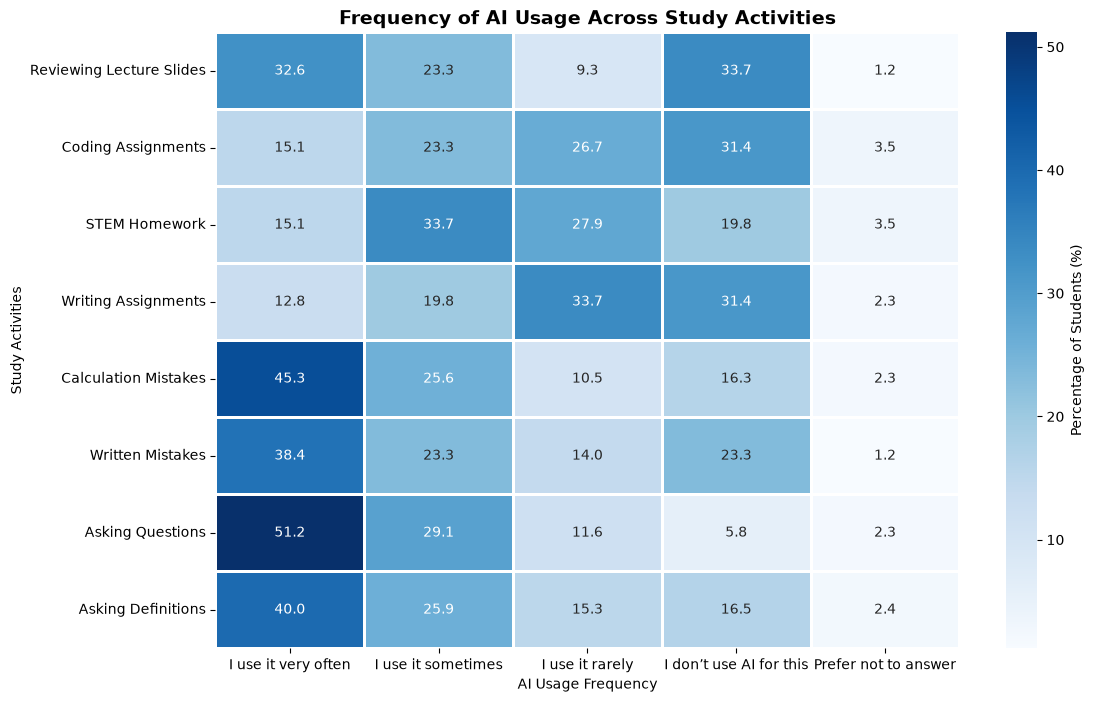

In [ ]:

# Create a heatmap
# Set figure size for better readability
plt.figure(figsize=(12, 8))

# cmap='Blues': Darker blue represents a higher percentage
# annot=True: Displays the percentages in each cell
# fmt='.1f': Shows percentages with 1 decimal place
# linewidths=1: Adds spacing between cells
sns.heatmap(percentage_survey, cmap='Blues', annot=True, fmt='.1f',
            linewidths=1, cbar_kws={'label': 'Percentage of Students (%)'})

# Add title and labels
plt.title('Frequency of AI Usage Across Study Activities', fontsize=14, fontweight='bold')
plt.xlabel('AI Usage Frequency')
plt.ylabel('Study Activities')
plt.show()



**Interpretation:**

Survey Question:
How often do you use AI in the given examples to study?

What we suspect:
We think students are more likely to use AI frequently for asking questions, finding definitions, and reviewing mistakes in their work than for completing coding, STEM homework, or writing-based assignments.

Our analysis:
We used responses from eight survey questions about how frequently students use AI for different study activities. Seven activities contain 86 responses each, while asking for definitions contains 85 responses.

We compared the frequency of AI use across these eight study activities. We grouped responses into Very Often, Sometimes, Rarely, Don't Use AI, and Prefer Not to Answer. We then calculated the percentage of students selecting each response and displayed the results using a heatmap.
Findings:
- 80.3% of students use AI very often or sometimes for asking questions or clarifying concepts.
- 70.9% use AI very often or sometimes for reviewing calculation mistakes.
- 65.9% use AI very often or sometimes for asking for definitions.
- 48.8% use AI very often or sometimes for STEM homework.
- 38.4% use AI very often or sometimes for completing coding assignments.
- 32.6% use AI very often or sometimes for writing assignments.

Conclusion:
Students use AI more frequently for understanding concepts and reviewing mistakes than for completing assignments directly. Asking questions and reviewing calculation mistakes are among the most common uses of AI. The results support our hypothesis.

#### Visualization 5: <title>

**What we want to learn:**

# Question: Deadline Pressure and AI Use

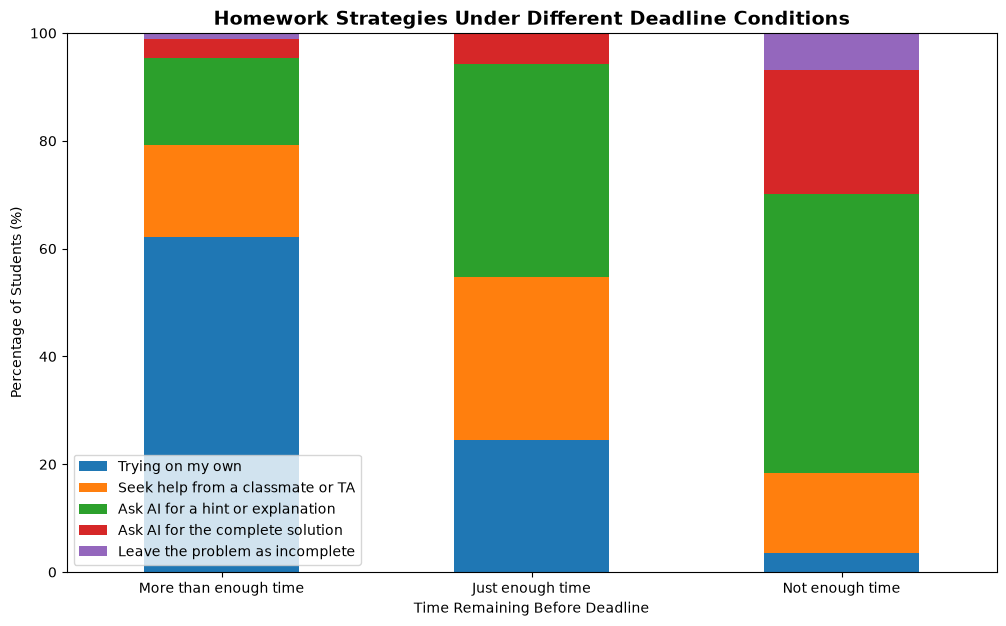

In [ ]:
# Create a 100% stacked bar chart to compare homework strategies under different deadline conditions
# Create the stacked bar chart
# stacked=True: Stacks different homework strategies into one bar
# Each bar represents 100% of responses for one deadline situation
percentage_homework.plot.bar(stacked=True, figsize=(12, 7))

# Add title and axis labels
plt.title('Homework Strategies Under Different Deadline Conditions', fontsize=14, fontweight='bold')
plt.xlabel('Time Remaining Before Deadline')
plt.ylabel('Percentage of Students (%)')

# Set the y-axis range from 0% to 100%
plt.ylim(0, 100)

# Rotate x-axis labels for readability
plt.xticks(rotation=0)

# Display the chart
plt.show()

**Interpretation:**

Survey Question:

If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take when you have more than enough time, just enough time, or not enough time before the deadline?

What we suspect:

We think students are more likely to ask AI for hints, explanations, or complete solutions as deadline pressure increases, rather than continuing to solve problems independently.

Our analysis:

We compared students' preferred homework strategies under three different deadline scenarios. We calculated the percentage of students choosing each strategy and displayed the results using a 100% stacked bar chart to show how the distribution of responses changes as available time decreases.

Findings:
When students have more than enough time, 19.5% prefer AI assistance.
When students have just enough time, 45.3% prefer AI assistance.
When students do not have enough time, 74.7% prefer AI assistance.
The percentage choosing to work independently decreases from 62.1% to 3.4% between the first and last scenarios.

Conclusion:

Students are increasingly likely to choose AI assistance as deadline pressure increases. The results suggest an association between having less time to complete homework and a greater preference for AI assistance.

#### Visualization 6: <title>

**What we want to learn:**

# Question: Does AI Reduce Stress Relative to Minutes Using AI

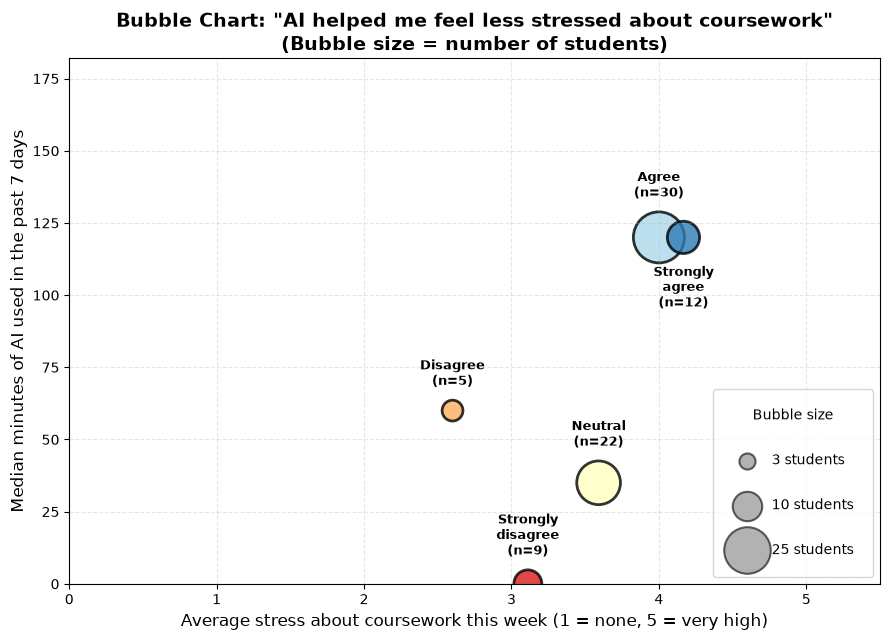

In [56]:
SCALE = 45

plt.figure(figsize=(9, 6.5))
plt.scatter(stress_avg, minutes_med,
            s=[n * SCALE for n in students],
            c=bubble_colors,
            alpha=0.8,
            edgecolors="black",
            linewidth=2)


below = {5}
for g, lab, n, x_, y_ in zip(groups, labels, students, stress_avg, minutes_med):
    offset = np.sqrt(n * SCALE) / 2 + 8
    if int(g) in below:
        plt.annotate(f"{lab}\n(n={n})", (x_, y_), xytext=(0, -offset), textcoords="offset points",
                     ha="center", va="top", fontweight="bold", fontsize=9)
    else:
        plt.annotate(f"{lab}\n(n={n})", (x_, y_), xytext=(0, offset), textcoords="offset points",
                     ha="center", va="bottom", fontweight="bold", fontsize=9)

plt.xlabel("Average stress about coursework this week (1 = none, 5 = very high)", fontsize=12)
plt.ylabel("Median minutes of AI used in the past 7 days", fontsize=12)
plt.title('Bubble Chart: "AI helped me feel less stressed about coursework"\n'
          "(Bubble size = number of students)", fontsize=14, fontweight="bold")

plt.grid(True, alpha=0.3, linestyle="--")


plt.xlim(0, 5.5)
plt.xticks(range(0, 6))
plt.ylim(0, max(minutes_med) * 1.35 + 20)


legend_sizes = [3, 10, 25]
legend_elements = [plt.scatter([], [], s=v * SCALE, c="gray", alpha=0.6, edgecolors="black",
                               linewidth=1.5, label=f"{v} students") for v in legend_sizes]
plt.legend(handles=legend_elements, title="Bubble size", loc="lower right",
           labelspacing=2.2, borderpad=1.4, frameon=True)

plt.tight_layout()
plt.show()

**Interpretation:**


Description: 
This bubble chart compares how stressed students are, how many minutes they used AI, and whether they feel AI helped them with stress, with each bubble representing a group of students who gave the same answer to "During this week, AI has helped me feel less stressed/anxious about my coursework" (strongly disagree, disagree, neutral, agree, strongly agree). The graph aims to compare the overall stress students may be feeling and seeing how AI might help reduce that stress. In doing so, students might be more inclined to use AI if it helps them both manage schoolwork and reduce stressful situations.
Note that Median was used over Mean due to a number of outliers in the data set

Hypothesis: 
Students who feel that AI helps reduce stress while doing schoolwork are more likely to use AI, and students who are more stressed during the week are more likely to feel that AI helps them. Students who disagree that AI reduces their stress use AI the least.


Analysis:
53 students answered both the AI-and-stress question and the minutes question. 
33 of them (62%) agreed or strongly agreed that AI helped them feel less stressed, 15 were neutral, and only 5 disagreed or strongly disagreed. 
The Agree group (23 students) and Strongly Agree group (10 students) each have a median of 120 minutes of AI use, three times the Neutral group's median of 40 minutes (15 students). 
This directly shows that students who believed that AI reduced workload stress tended to use it more. 
Although this might not have been the only factor contributing to the increase of AI usage, there is a strong correlation in the visualization that implies that it could have influenced it.

Conclusion: 
Students who agree that AI helps them feel less stressed use AI more than students who feel neutral about it. 
The more a student agrees that AI makes their schoolwork less stressful the more minutes they tend to have using AI. 
The groups who disagree are too small to draw any sizable conclusions from.

#### Visualization 7: <title>

**What we want to learn:**

# Question: Is there a correlation between minutes using AI Relative to Time Spent Procrasinating

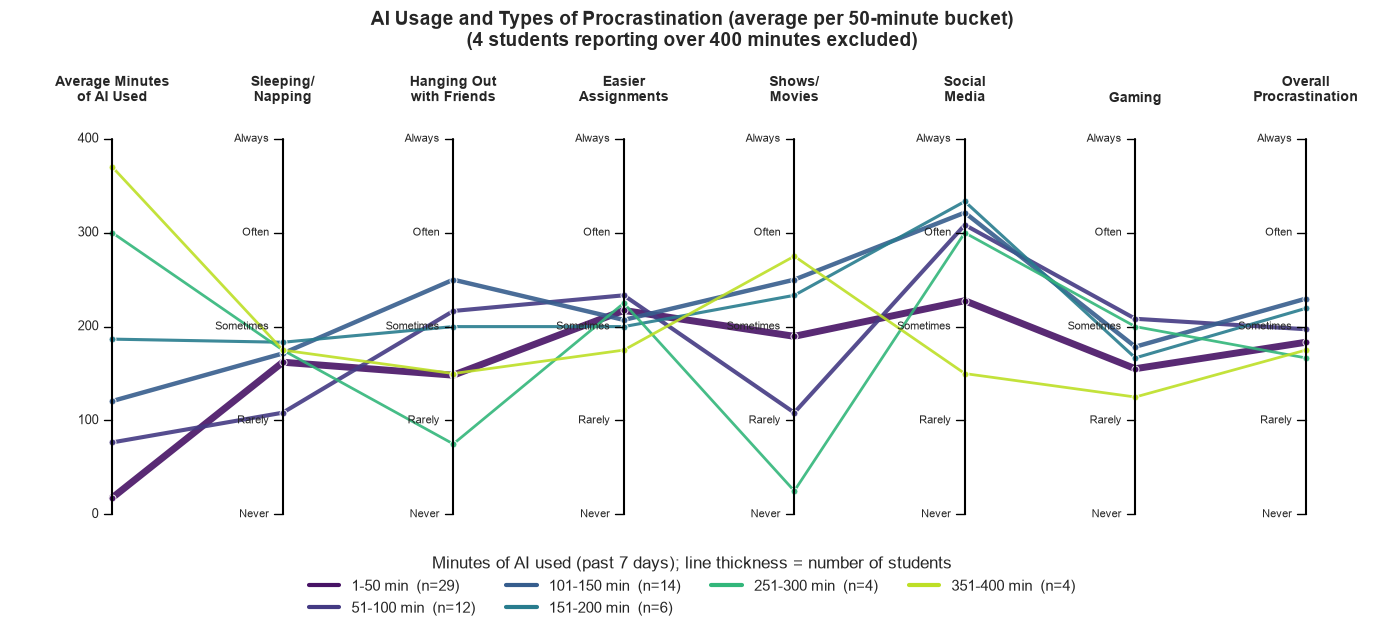

In [57]:
sns.set_theme(style="white", font_scale=1.0)

long_df = (scaled_df[columns].reset_index().melt(id_vars="bucket", var_name="axis", value_name="value"))
long_df["bucket"] = long_df["bucket"].astype(str)
long_df["x"] = long_df["axis"].map(dict(zip(columns, x)))

n_max = bucket_n.max()
bucket_lw = {str(b): 1.5 + 3.5 * bucket_n[b] / n_max for b in bucket_n.index}
palette = {str(b): c for b, c in bucket_colors.items()}

fig, pcp = plt.subplots(figsize=(14, 6.5))
sns.lineplot(data=long_df, x="x", y="value", hue="bucket", palette=palette,
             size="bucket", sizes=bucket_lw, estimator=None, sort=False,
             marker="o", markersize=5, alpha=0.9, legend=False, ax=pcp)

for xi, col in zip(x, columns):
    pcp.plot([xi, xi], [0, 1], color="black", linewidth=1.5)
    pcp.text(xi, 1.09, col, ha="center", va="bottom", fontsize=10, fontweight="bold")

for m in ai_ticks:
    pos = m / ai_cutoff
    pcp.plot([-0.05, 0], [pos, pos], color="black", linewidth=1)
    pcp.text(-0.08, pos, str(m), ha="right", va="center", fontsize=9)

for xi in x[1:]:
    for score, label in enumerate(["Never", "Rarely", "Sometimes", "Often", "Always"]):
        pcp.plot([xi - 0.05, xi], [score / 4, score / 4], color="black", linewidth=1)
        pcp.text(xi - 0.08, score / 4, label, ha="right", va="center", fontsize=8)

pcp.set_xlim(-0.6, len(columns) - 0.6)
pcp.set_ylim(-0.05, 1.2)
pcp.axis("off")
plt.title(f"AI Usage and Types of Procrastination (average per {bucket_size}-minute bucket)\n"
          f"({n_removed} students reporting over {ai_cutoff} minutes excluded)",
          fontsize=14, fontweight="bold", y=1.02)

legend_handles = [Line2D([0], [0], color=palette[str(b)], lw=3, label=f"{b}  (n={bucket_n[b]})") for b in bucket_n.index]
pcp.legend(handles=legend_handles, title="Minutes of AI used (past 7 days); line thickness = number of students",
           loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

**Interpretation:**


Description: 
This parallel coordinate plot compares minutes of AI used with time spent procrastinating with each line representing one student and each axis representing a different type of procrastination: sleeping/napping, hanging out with friends, completing easier or other assignments, watching shows/movies, social media (Instagram, TikTok, etc.), and gaming. Lines that rise or fall together across the axis show which kinds of procrastination tend to go along with heavier or lighter AI use. Where lines cluster tightly, a pattern is shared across students. Where they spread out or cross, the relationship is weaker or varies by person.

Hypothesis: 
Students who use AI for more minutes spend less time procrastinating overall, and certain types of procrastination, such as completing easier assignments, are less likely to use as much AI as others, such as gaming or social media.


Analysis:
We did not find a clear relationship between how much students use AI and how much they procrastinate. 
The lines for different AI-use groups overlap and cross on every axis, with no group consistently higher or lower. 
The differences between the highest buckets come from only 3-4 students each, so they are more likely noise than real patterns. 
What the data does show clearly is that social media is the most common way students procrastinate, regardless of how much they use AI. 
Additionally students who used more AI were very slightly more likely to report procrastinating. 
However, there was too small a sample size to make a clear correlation. 
A larger sample would be needed to rule out a small relationship.

Conclusion: 
There is no clear relationship between how many minutes students used AI and how they procrastinate. 
AI usage does not appear to depend on how a student procrastinates, but social media is the dominant procrastination activity across all AI usage levels.
It does seem that students who used more AI reported more procrastination, but a larger sample size would be best to verify that.

#### Visualization 8: <title>

**What we want to learn:**

# Question: Do AI deterrents differ by year?

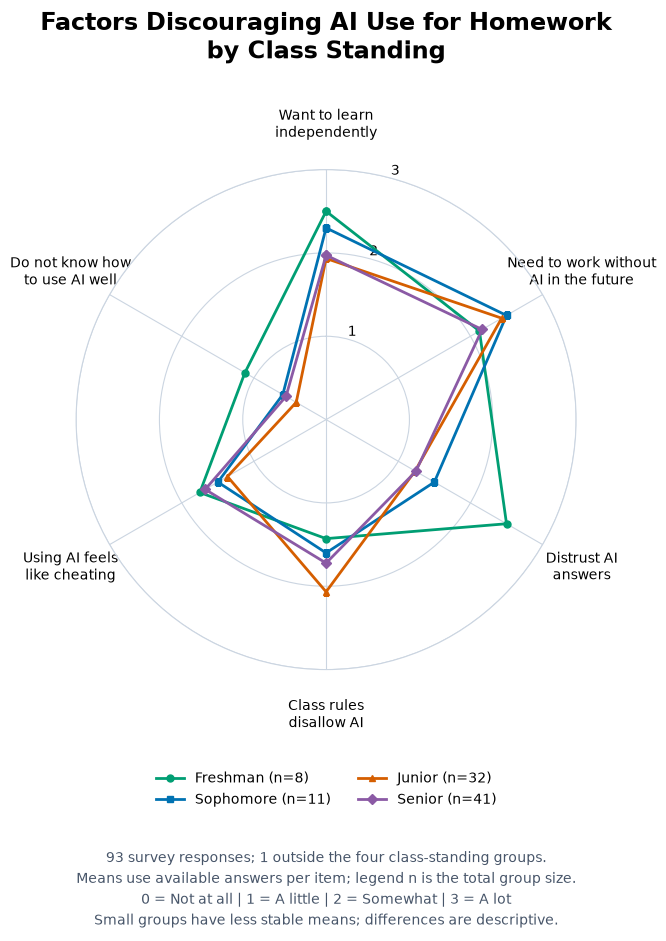

Group mean ratings:
                learn_myself  future_independence  distrust_answers  class_rules  feels_like_cheating  lack_of_ai_skills
class_standing                                                                                                          
Freshman                 2.5                 2.12               2.5         1.43                 1.75               1.12
Sophomore                2.3                  2.5               1.5          1.6                  1.5                0.6
Junior                  1.93                 2.43              1.23         2.07                 1.37               0.41
Senior                  1.97                 2.16              1.24         1.72                 1.68               0.56

Valid responses per group and factor:
                learn_myself  future_independence  distrust_answers  class_rules  feels_like_cheating  lack_of_ai_skills
class_standing                                                                                

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

order = list(factors)
year_order = ['Freshman', 'Sophomore', 'Junior', 'Senior']
# Use row positions because clean_factors is indexed by original Excel row.
class_standing = pd.Series(
    data['What is your current class standing?'].astype('string').str.strip().to_numpy(),
    index=clean_factors.index, name='class_standing',
)
year_data = clean_factors[order].join(class_standing)
year_data = year_data[year_data['class_standing'].isin(year_order)]
year_means = year_data.groupby('class_standing')[order].mean().reindex(year_order)
year_counts = year_data.groupby('class_standing')[order].count().reindex(year_order)
year_sizes = year_data.groupby('class_standing').size().reindex(year_order, fill_value=0)
label_text = [
    'Want to learn\nindependently', 'Need to work without\nAI in the future',
    'Distrust AI\nanswers', 'Class rules\ndisallow AI',
    'Using AI feels\nlike cheating', 'Do not know how\nto use AI well',
]
angles = np.linspace(0, 2 * np.pi, len(order), endpoint=False)
closed_angles = np.r_[angles, angles[0]]
fig, ax = plt.subplots(figsize=(11, 10), subplot_kw={'projection': 'polar'})
fig.subplots_adjust(left=0.20, right=0.80, top=0.80, bottom=0.30)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_ylim(0, 3)
ax.set_yticks([1, 2, 3])
ax.set_rlabel_position(15)
ax.set_xticks(angles)
ax.set_xticklabels(label_text, fontsize=10)
ax.tick_params(axis='x', pad=22)
ax.grid(color='#cbd5e1', linewidth=0.8)
ax.spines['polar'].set_color('#cbd5e1')
colors = ['#009E73', '#0072B2', '#D55E00', '#8B5AA5']
markers = ['o', 's', '^', 'D']
for year, color, marker in zip(year_order, colors, markers):
    values = year_means.loc[year].astype(float).to_numpy()
    ax.plot(closed_angles, np.r_[values, values[0]], color=color,
            marker=marker, linewidth=2, markersize=5,
            label=f'{year} (n={year_sizes[year]})')
fig.suptitle('Factors Discouraging AI Use for Homework\nby Class Standing',
             fontsize=17, fontweight='bold', y=0.96)
fig.legend(*ax.get_legend_handles_labels(), loc='lower center',
           bbox_to_anchor=(0.5, 0.15), ncol=2, frameon=False)
excluded_year_n = len(data) - len(year_data)
fig.text(0.5, 0.045,
         f'{len(data)} survey responses; {excluded_year_n} outside the four class-standing groups.\n'
         'Means use available answers per item; legend n is the total group size.\n'
         '0 = Not at all | 1 = A little | 2 = Somewhat | 3 = A lot\n'
         'Small groups have less stable means; differences are descriptive.',
         ha='center', fontsize=10, color='#475569', linespacing=1.5)
radar_path = output_dir / 'deterrents_radar.png'
fig.savefig(radar_path, dpi=200, facecolor='white')
plt.show()
plt.close(fig)
print('Group mean ratings:')
print(year_means.round(2).to_string())
print('\nValid responses per group and factor:')
print(year_counts.to_string())
print('\nSaved:', radar_path.name)


**What we want to learn:** How do the six deterrents differ across years?

Each color and marker represents a year. Lines show mean scores on the same 0–3 scale. The legend gives group sizes, and the output gives valid counts per item. The chart excludes one concurrent student whose year is unclear.

**Interpretation:** Future independence had the highest mean for sophomores (2.50), juniors (2.43), and seniors (2.16). For freshmen, independent learning and distrust of AI tied at 2.50. Difficulty using AI had the lowest mean in every group.

Freshman (n=8) and sophomore (n=11) groups are small. The chart describes differences; year-group significance has not been tested.


### II. Formulating and Testing Hypotheses

*At least 3 hypotheses. At least one correlation analysis and one chi-squared test.*

#### Hypothesis 1: <statement>

**Test and justification:**

chi squared test with the mosaic plot in visualization #4

**Result and conclusion:**

#### Hypothesis 2: <statement>

**Test and justification:**

**Result and conclusion:**

### Hypothesis 3: Learning-related ratings are higher than trust/skill ratings

**Scores:**

- Learning score = average of independent learning and future independence.
- Trust/skill score = average of distrust and difficulty using AI.
- Difference = learning score − trust/skill score.

**Test and justification:** Use complete answers to all four items. Scores are paired within each respondent. Run a two-sided Wilcoxon signed-rank test at α = 0.05, using an asymptotic calculation with tie and continuity corrections and excluding zero differences from ranking. A location-shift interpretation requires approximately symmetric differences.

An exact two-sided sign test checks whether positive and negative differences are equally likely, without requiring symmetry. Both tests assume independent respondents. These custom scores and tests are exploratory.


**Result and conclusion:**

In [ ]:
from scipy import stats
import json

required = ['learn_myself', 'future_independence', 'distrust_answers', 'lack_of_ai_skills']
paired = clean_factors[required].dropna().astype(float).copy()
paired['learning_score'] = paired[['learn_myself', 'future_independence']].mean(axis=1)
paired['trust_skill_score'] = paired[['distrust_answers', 'lack_of_ai_skills']].mean(axis=1)
paired['difference'] = paired['learning_score'] - paired['trust_skill_score']
difference = paired['difference'].to_numpy()
n_positive = int((difference > 0).sum())
n_negative = int((difference < 0).sum())
n_zero = int((difference == 0).sum())
n_nonzero = n_positive + n_negative
if n_nonzero == 0:
    raise ValueError('All paired differences are zero; no signed-rank or sign test is informative.')
wilcoxon_result = stats.wilcoxon(
    difference, alternative='two-sided', zero_method='wilcox',
    method='asymptotic', correction=True,
)
sign_result = stats.binomtest(n_positive, n_nonzero, p=0.5, alternative='two-sided')
nonzero = difference[difference != 0]
ranks = stats.rankdata(np.abs(nonzero))
w_plus = float(ranks[nonzero > 0].sum())
w_minus = float(ranks[nonzero < 0].sum())
rank_biserial = (w_plus - w_minus) / (w_plus + w_minus)
test_results = {
    'alpha': 0.05, 'alternative': 'two-sided',
    'complete_pairs': len(paired), 'excluded_incomplete_responses': len(data) - len(paired),
    'positive_differences': n_positive, 'negative_differences': n_negative,
    'zero_differences': n_zero, 'nonzero_pairs': n_nonzero,
    'learning_score_mean': float(paired['learning_score'].mean()),
    'trust_skill_score_mean': float(paired['trust_skill_score'].mean()),
    'mean_paired_difference': float(np.mean(difference)),
    'median_paired_difference': float(np.median(difference)),
    'difference_q1': float(np.quantile(difference, 0.25)),
    'difference_q3': float(np.quantile(difference, 0.75)),
    'wilcoxon_statistic': float(wilcoxon_result.statistic),
    'wilcoxon_p_value': float(wilcoxon_result.pvalue),
    'wilcoxon_method': 'tie-corrected asymptotic; continuity correction; zero_method=wilcox',
    'matched_pairs_rank_biserial': rank_biserial,
    'exact_sign_test_p_value': float(sign_result.pvalue),
}
print(json.dumps(test_results, indent=2))
print('\nObserved paired-difference distribution:')
print(paired['difference'].value_counts().sort_index().to_string())
paired.to_csv(output_dir / 'deterrents_paired_scores.csv')
(output_dir / 'deterrents_test_results.json').write_text(json.dumps(test_results, indent=2) + '\n')


{
  "alpha": 0.05,
  "alternative": "two-sided",
  "complete_pairs": 83,
  "excluded_incomplete_responses": 10,
  "positive_differences": 60,
  "negative_differences": 2,
  "zero_differences": 21,
  "nonzero_pairs": 62,
  "learning_score_mean": 2.1566265060240966,
  "trust_skill_score_mean": 0.9939759036144579,
  "mean_paired_difference": 1.1626506024096386,
  "median_paired_difference": 1.5,
  "difference_q1": 0.0,
  "difference_q3": 2.0,
  "wilcoxon_statistic": 31.5,
  "wilcoxon_p_value": 2.680960554745181e-11,
  "wilcoxon_method": "tie-corrected asymptotic; continuity correction; zero_method=wilcox",
  "matched_pairs_rank_biserial": 0.967741935483871,
  "exact_sign_test_p_value": 8.474124180146703e-16
}

Observed paired-difference distribution:
difference
-1.5     1
-0.5     1
 0.0    21
 0.5     5
 1.0    12
 1.5    18
 2.0    14
 2.5     8
 3.0     3


716

**Result and conclusion:** For 83 complete pairs, learning scores averaged 2.16 and trust/skill scores averaged 0.99. The mean paired difference was 1.16. Wilcoxon W = 31.5, p = 2.68e-11; sign-test p = 8.47e-16. The results support higher learning-related ratings. Ten incomplete responses were excluded.


#### Hypothesis 4: Class-rule and cheating-related deterrents are associated

**H0:** The two deterrents are independent.

**H1:** The two deterrents are associated.

**Grouping:** Lower = Not at all / A little. Higher = Somewhat / A lot. This split separates weaker and stronger barriers but loses detail.

**Test and justification:** Use a 2 × 2 chi-squared independence test with Yates correction at α = 0.05. Include respondents who answered both items. Each respondent enters one cell, and all expected counts must be at least 5. Responses are assumed independent.

The class-rule item measures a reported barrier, not the actual course policy.


In [ ]:
from scipy import stats

chi_answers = clean_factors[['class_rules', 'feels_like_cheating']].dropna()
chi_group_map = {0: 'Lower deterrence', 1: 'Lower deterrence',
                 2: 'Higher deterrence', 3: 'Higher deterrence'}
chi_groups = chi_answers.apply(lambda column: column.map(chi_group_map))
chi_levels = ['Lower deterrence', 'Higher deterrence']
chi_observed = pd.crosstab(
    chi_groups['class_rules'], chi_groups['feels_like_cheating'],
).reindex(index=chi_levels, columns=chi_levels, fill_value=0)
chi_observed.index.name = 'Class-rule deterrence'
chi_observed.columns.name = 'Cheating-related deterrence'
if (chi_observed.sum(axis=0) == 0).any() or (chi_observed.sum(axis=1) == 0).any():
    raise ValueError('Both deterrence groups must be represented for each item.')
chi_statistic, chi_p_value, chi_dof, chi_expected_array = stats.chi2_contingency(
    chi_observed, correction=True,
)
chi_expected = pd.DataFrame(
    chi_expected_array, index=chi_observed.index, columns=chi_observed.columns,
)
if (chi_expected_array < 5).any():
    raise ValueError('Expected cell counts are below 5; reassess the chi-squared method.')
chi_higher_percent = 100 * chi_observed['Higher deterrence'] / chi_observed.sum(axis=1)
print(f'Complete responses: {len(chi_answers)}; excluded: {len(data) - len(chi_answers)}')
print('Observed counts (rows = class rules; columns = cheating):')
print(chi_observed.to_string())
print('\nExpected counts:')
print(chi_expected.round(2).to_string())
print(f'\nPearson chi-squared with Yates correction: chi2({chi_dof}) = '
      f'{chi_statistic:.4f}, p = {chi_p_value:.6g}')
print('\nHigher cheating-related deterrence within each class-rule group (%):')
print(chi_higher_percent.round(1).to_string())


Complete responses: 84; excluded: 9
Observed counts (rows = class rules; columns = cheating):
Cheating-related deterrence  Lower deterrence  Higher deterrence
Class-rule deterrence                                           
Lower deterrence                           22                  7
Higher deterrence                          19                 36

Expected counts:
Cheating-related deterrence  Lower deterrence  Higher deterrence
Class-rule deterrence                                           
Lower deterrence                        14.15              14.85
Higher deterrence                       26.85              28.15

Pearson chi-squared with Yates correction: chi2(1) = 11.3720, p = 0.000745598

Higher cheating-related deterrence within each class-rule group (%):
Class-rule deterrence
Lower deterrence     24.1
Higher deterrence    65.5


**Result and conclusion:** Among 84 complete responses, higher cheating-related deterrence was reported by 65.5% of the higher class-rule group and 24.1% of the lower group. χ²(1) = 11.37, p = 0.000746, with Yates correction. All expected counts exceeded 5. Reject H0 at α = 0.05.

The two reported barriers are associated in this sample. This exploratory analysis does not establish causation.


## Overall Conclusion

*Summarize findings and relate them back to the original questions.*

## Group Contributions

| Member | Contribution |
|---|---|
| jcarb044 | |
| jprad022 | |
| jyu356 | |
| kaung006 | |
| slian088 | |